# Customer Churn Analysis — Telco

Exploratory data analysis and a logistic-regression model that predicts customer churn and surfaces the main churn drivers, on the public IBM Telco Customer Churn dataset (7,043 customers).

**Author:** Hitesh Bharambe

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
    roc_auc_score, roc_curve, accuracy_score, precision_score,
    recall_score, f1_score)

sns.set_theme(style='whitegrid')
PALETTE = ['#4C72B0', '#DD8452']

## 2. Load & clean

`TotalCharges` is blank for new customers (tenure 0), so it loads as text — coerce it to numeric and fill those blanks with 0. Encode the target and drop the non-predictive `customerID`.

In [2]:
df = pd.read_csv('../data/Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df['Churn'] = (df['Churn'] == 'Yes').astype(int)
df = df.drop(columns=['customerID'])
print(f'{len(df):,} rows, {df.shape[1]} columns')
print(f"Overall churn rate: {df['Churn'].mean():.1%}")
df.head()

7,043 rows, 20 columns
Overall churn rate: 26.5%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 3. Exploratory data analysis

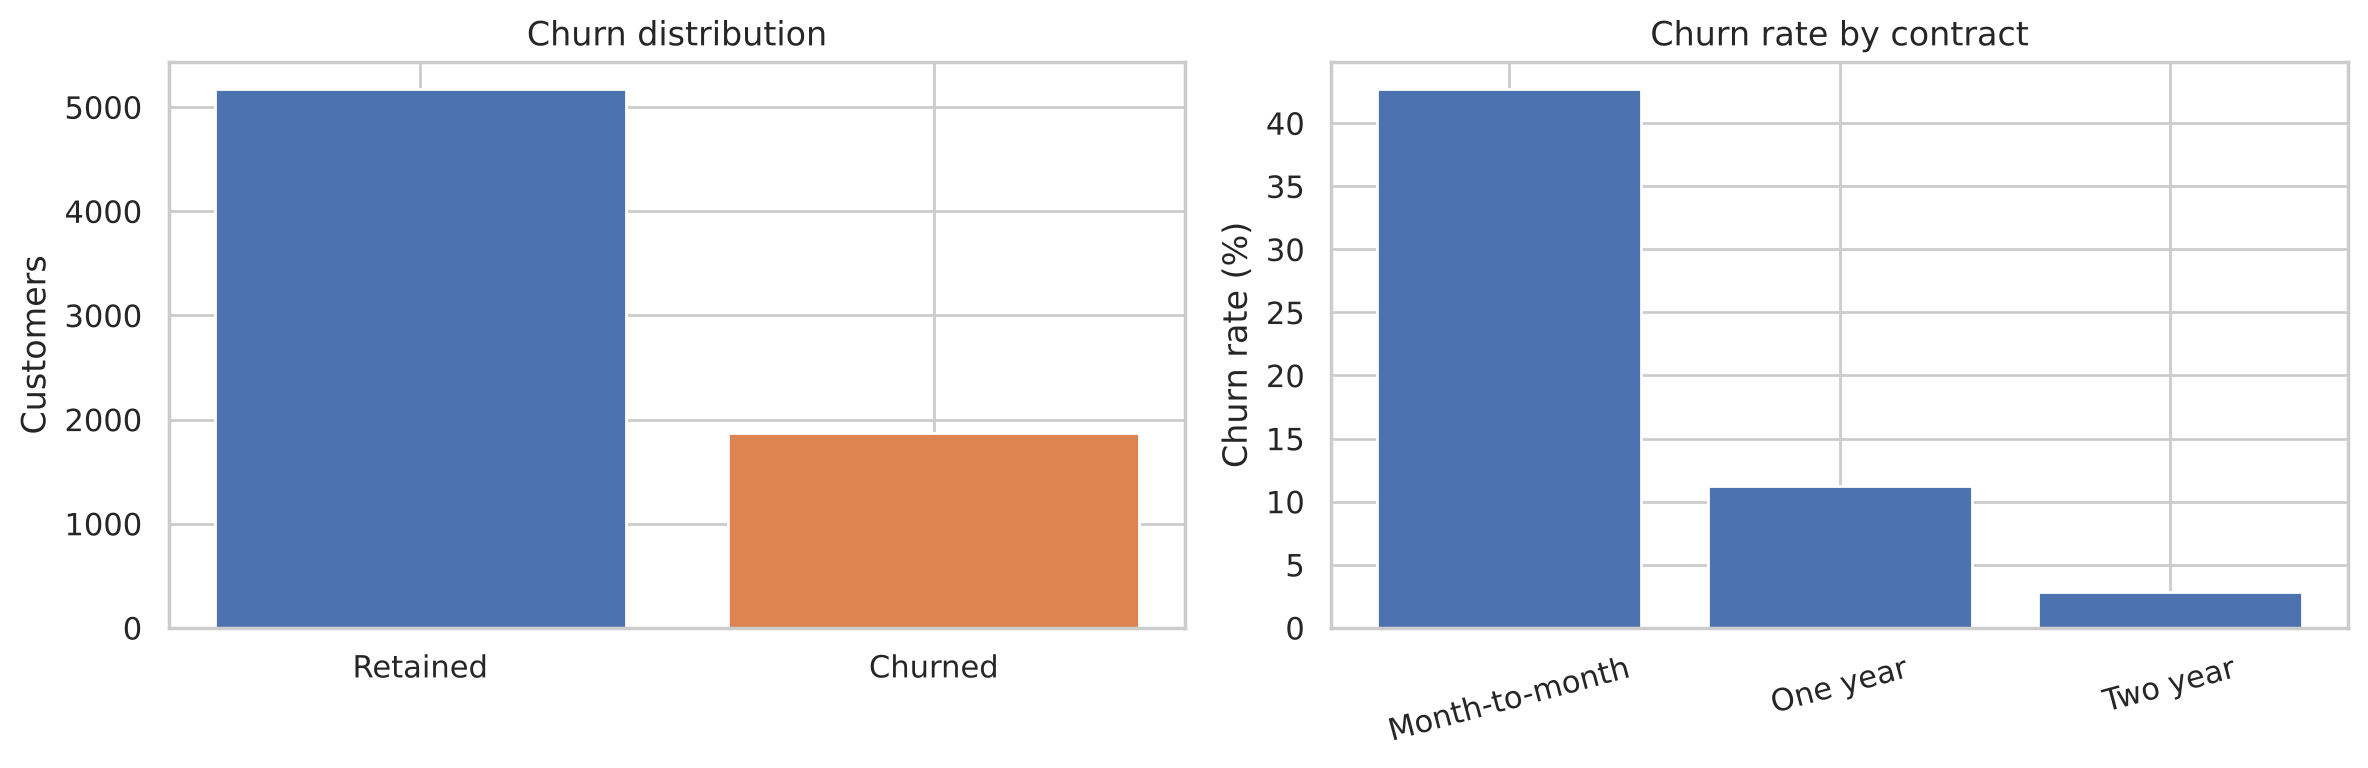

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = df['Churn'].map({0: 'Retained', 1: 'Churned'}).value_counts()
axes[0].bar(counts.index, counts.values, color=PALETTE)
axes[0].set_title('Churn distribution'); axes[0].set_ylabel('Customers')
rate = df.groupby('Contract')['Churn'].mean().sort_values(ascending=False)
axes[1].bar(rate.index, rate.values*100, color='#4C72B0')
axes[1].set_title('Churn rate by contract'); axes[1].set_ylabel('Churn rate (%)')
axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

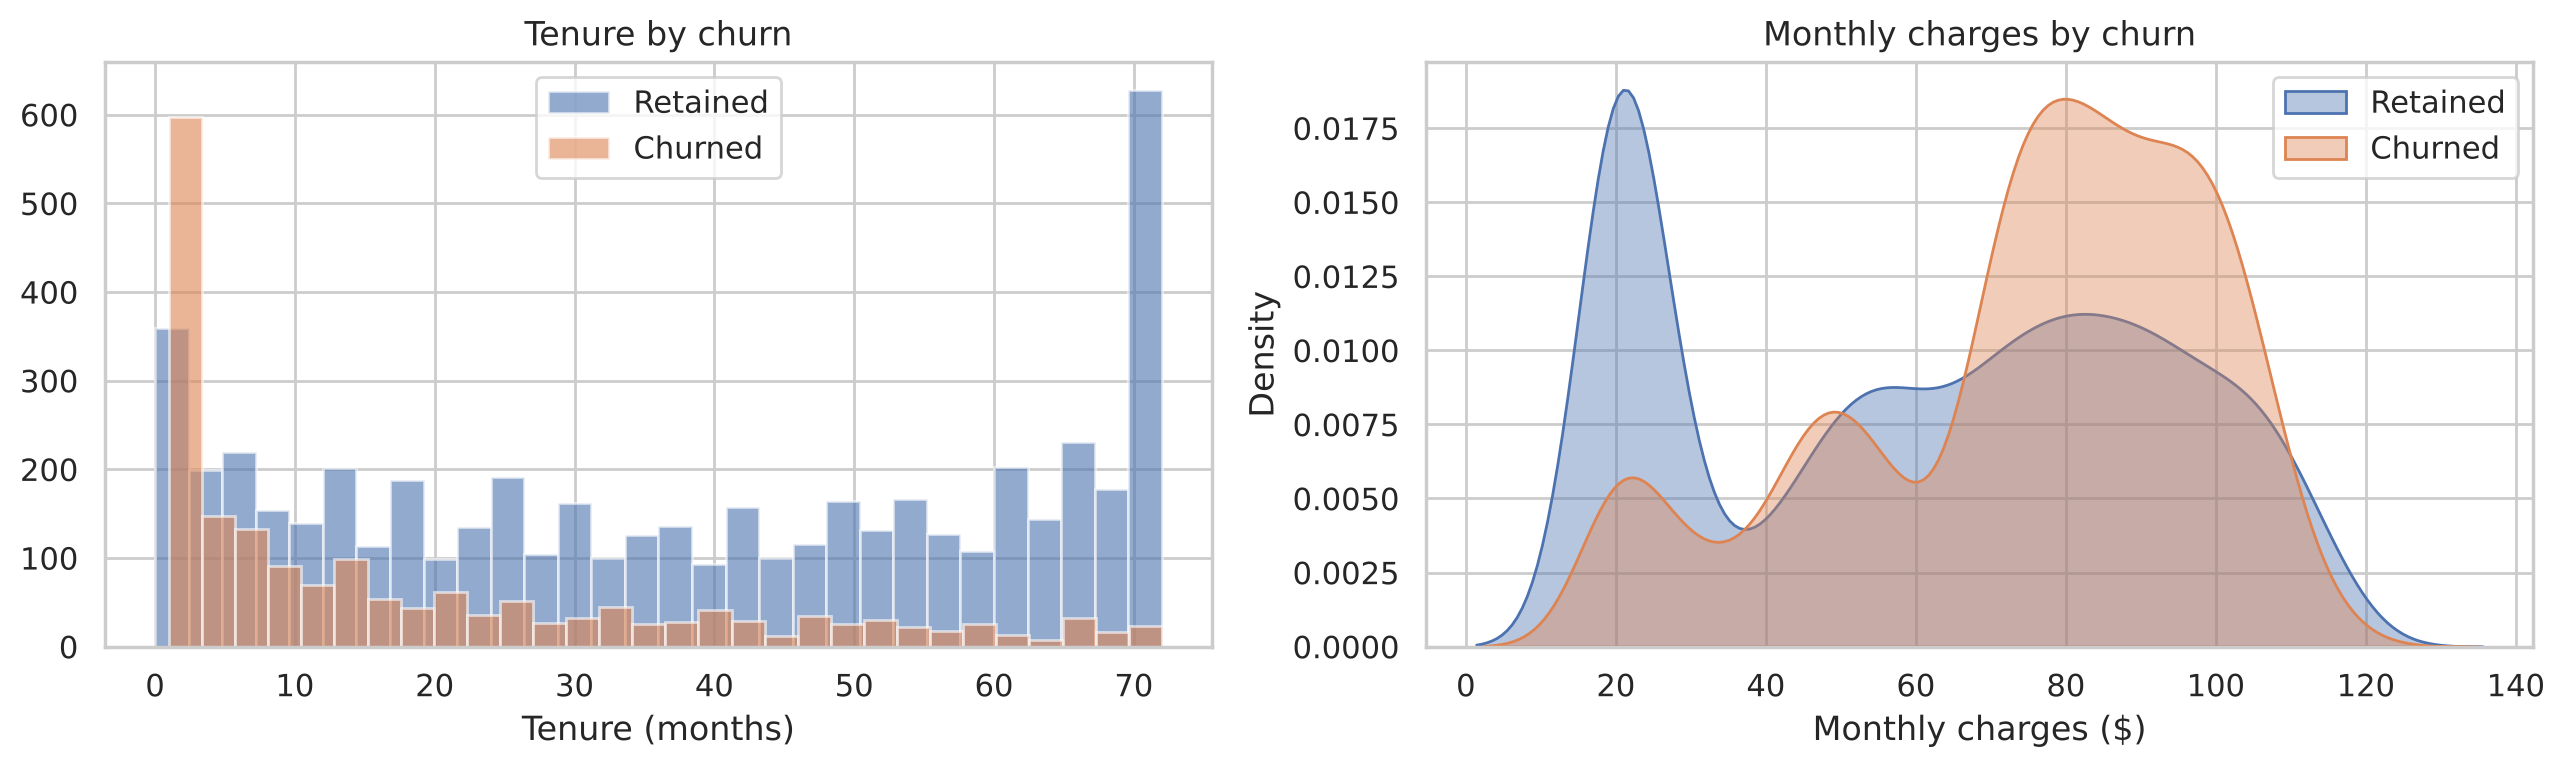

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, grp in df.groupby('Churn'):
    axes[0].hist(grp['tenure'], bins=30, alpha=0.6,
                 label='Churned' if label else 'Retained', color=PALETTE[label])
    sns.kdeplot(grp['MonthlyCharges'], ax=axes[1], fill=True, alpha=0.4,
                label='Churned' if label else 'Retained', color=PALETTE[label])
axes[0].set_title('Tenure by churn'); axes[0].set_xlabel('Tenure (months)'); axes[0].legend()
axes[1].set_title('Monthly charges by churn'); axes[1].set_xlabel('Monthly charges ($)'); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Feature engineering

One-hot encode categoricals (`drop_first` to avoid collinearity) and standard-scale the three continuous features.

In [5]:
y = df['Churn']
X = pd.get_dummies(df.drop(columns=['Churn']), drop_first=True)
numeric = ['tenure', 'MonthlyCharges', 'TotalCharges']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[numeric] = scaler.fit_transform(X_train[numeric])
X_test[numeric] = scaler.transform(X_test[numeric])
print(X_train.shape, X_test.shape)

(5634, 30) (1409, 30)


## 5. Model & evaluation

Logistic regression with `class_weight='balanced'` to handle the churn imbalance. Tuned to catch churners (recall).

In [6]:
model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
print(f'ROC-AUC : {roc_auc_score(y_test, y_proba):.3f}')
print(classification_report(y_test, y_pred, target_names=['Retained', 'Churned']))

ROC-AUC : 0.842
              precision    recall  f1-score   support

    Retained       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



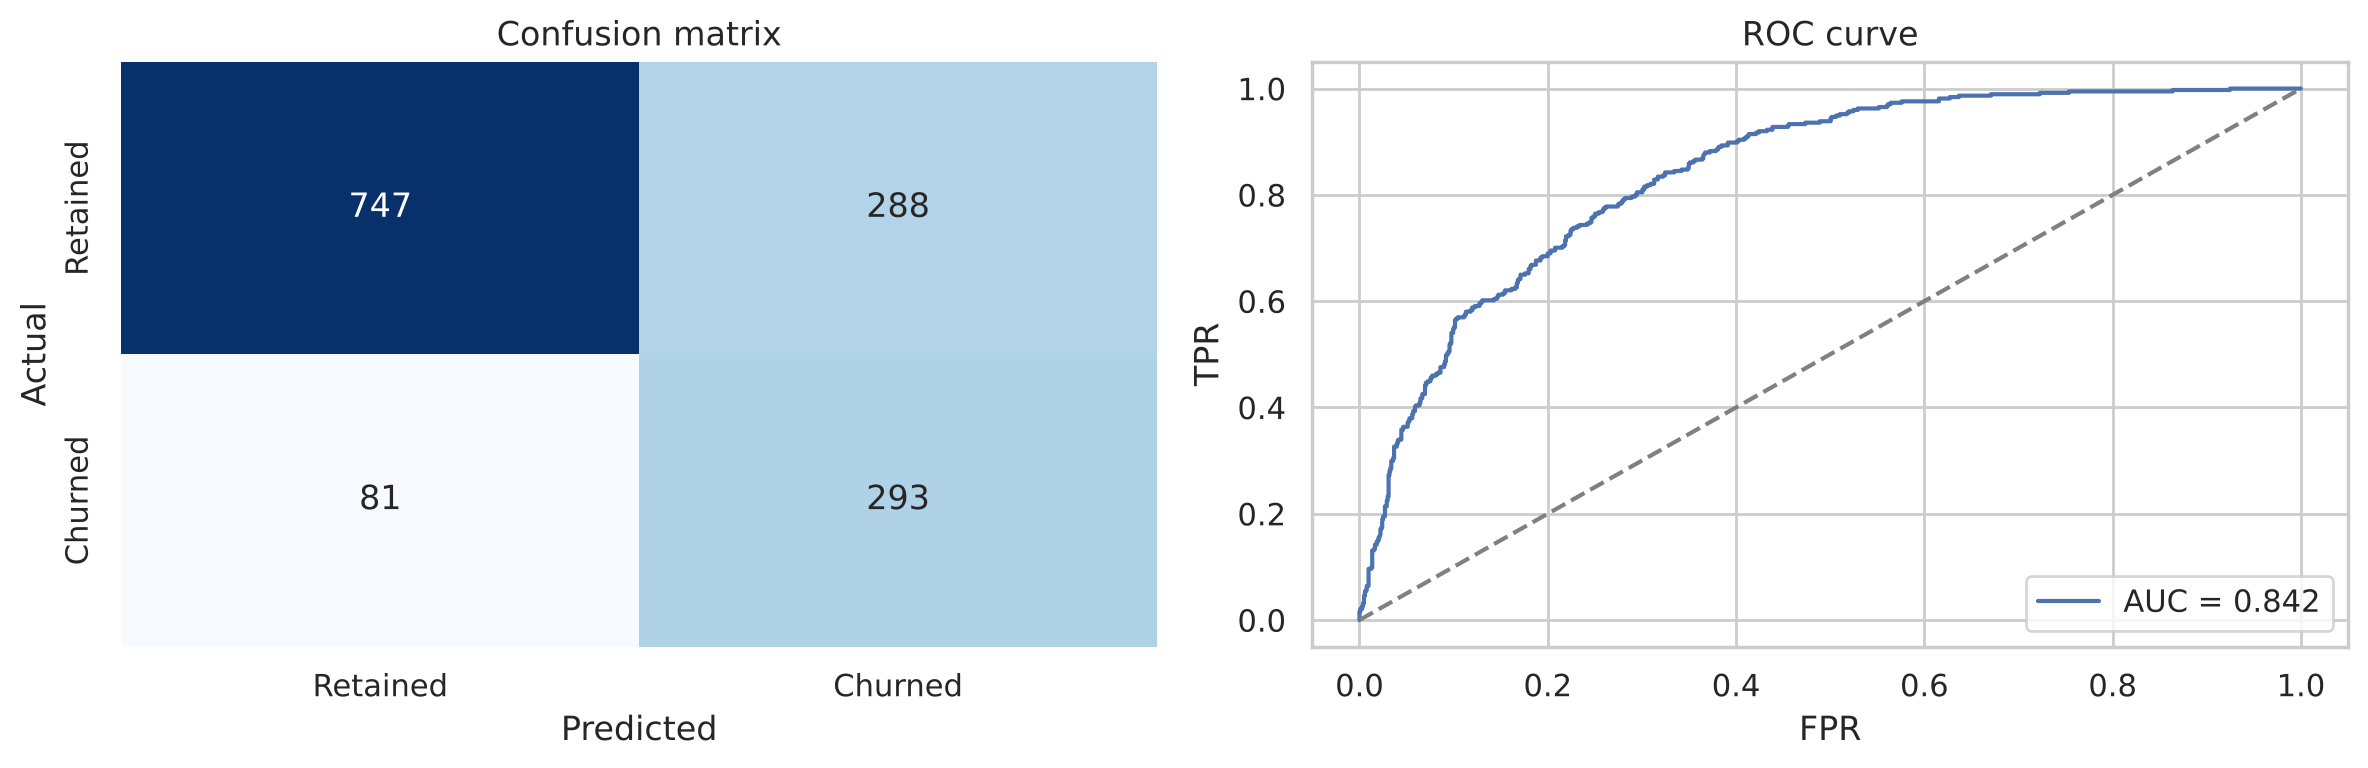

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Retained','Churned'], yticklabels=['Retained','Churned'], ax=axes[0])
axes[0].set_title('Confusion matrix'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='#4C72B0', label=f'AUC = {roc_auc_score(y_test, y_proba):.3f}')
axes[1].plot([0,1],[0,1],'--',color='grey')
axes[1].set_title('ROC curve'); axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR'); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

## 6. Churn drivers

Interpret the model via its coefficients and odds ratios.

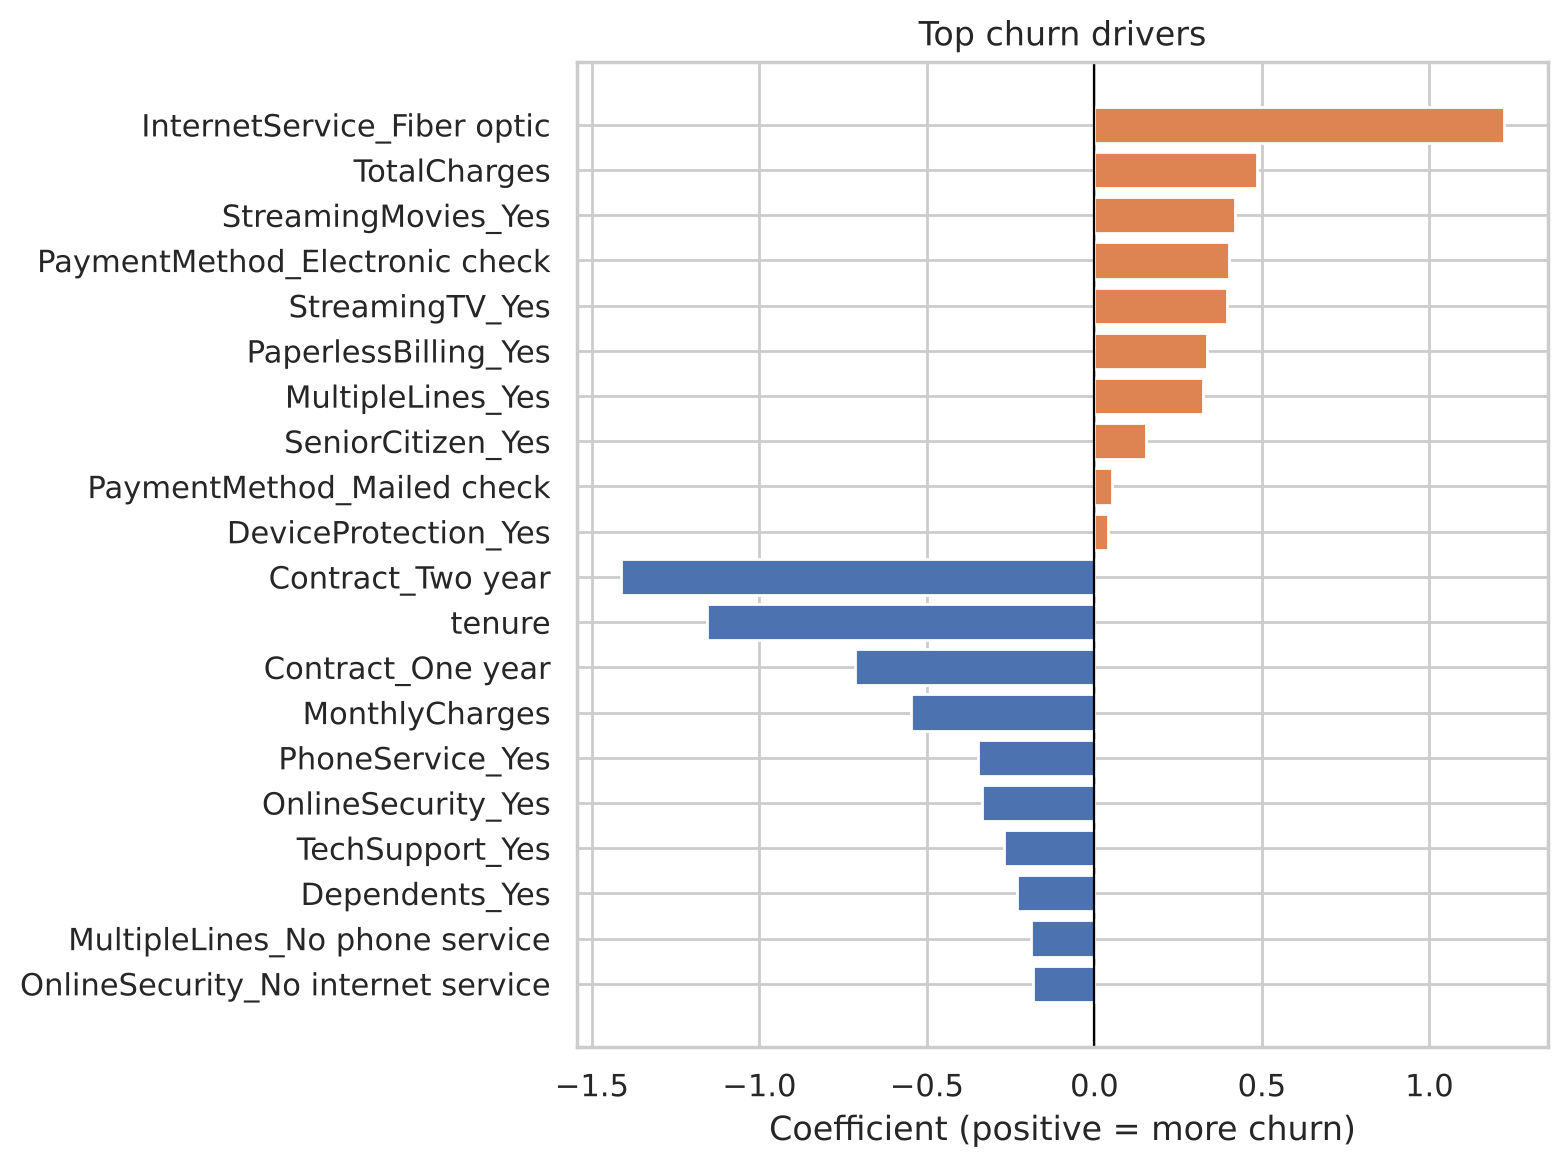

,feature,coef,odds_ratio
0,InternetService_Fiber optic,1.222352,3.395
1,TotalCharges,0.486541,1.627
2,StreamingMovies_Yes,0.420611,1.523
3,PaymentMethod_Electronic check,0.402478,1.496
4,StreamingTV_Yes,0.395359,1.485
5,PaperlessBilling_Yes,0.336449,1.400
6,MultipleLines_Yes,0.324742,1.384
7,SeniorCitizen_Yes,0.153869,1.166


In [8]:
coefs = (pd.DataFrame({'feature': X.columns, 'coef': model.coef_[0]})
         .sort_values('coef', ascending=False).reset_index(drop=True))
coefs['odds_ratio'] = np.exp(coefs['coef']).round(3)
drivers = pd.concat([coefs.head(10), coefs.tail(10).iloc[::-1]])
colors = ['#DD8452' if c > 0 else '#4C72B0' for c in drivers['coef']]
plt.figure(figsize=(8, 6))
plt.barh(drivers['feature'], drivers['coef'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top churn drivers'); plt.xlabel('Coefficient (positive = more churn)')
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()
coefs.head(8)

## Takeaways

- **Highest-risk segment:** month-to-month, fiber-optic customers paying by electronic check.
- **Strongest retention lever:** moving customers onto one- or two-year contracts.
- Longer tenure steadily reduces churn risk.
- The model catches ~78% of real churners (ROC-AUC 0.84), suitable for targeting a retention campaign.